# Problem Analysis Workshop C — Transformation/Linear Regression

**Course:** PROG8431 — Data Analysis, Mathematics, Modeling and Algorithms

**Team Members:**
- Ubaid Ullah — 9110715
- Rangeetha — 9081357
- Koushik Balne — 9087547






## Problem Analysis Statement

Nitrogen is the most widely used fertilizer nutrient and often a crop's largest fertilizer cost, yet the soil nitrogen level crops need varies widely. In our data, average N ranges from about 19 for lentil and pomegranate to about 118 for cotton. If we can't explain these differences, fertilizer has to be planned crop by crop from experience, which risks over-applying an expensive input.

**Problem:** we do not know which crop characteristics and growing conditions explain the soil nitrogen (N) level at which a crop grows well, or how accurately N can be predicted for a new field.

**Objective:** identify the variables that explain N and measure how well a regression model predicts it on unseen data.

**Scope:** Our Crop Analyzer project data , augmented with outside sources, analysed with transformations, validation and regression

### Approach

- **Data:** the Crop Recommendation dataset (2,200 rows, 22 crops × 100) with soil nutrients (N, P, K), temperature, humidity, pH and rainfall.
- **Augmentation:** FAO EcoCrop growing requirements and Statistics Canada crop area and value, joined on crop name, giving a study file of 25+ usable variables.
- **Method:** an 80/20 train/test split, two simple linear regressions, then a multiple linear regression narrowed down with backward selection.

## How Transformations and Regression Help the Project

Together they take the Crop Analyzer from describing the data (what each crop's conditions look like) to prediction (how much nitrogen a crop will need, and why). That is the step from descriptive to predictive analysis in the class slides.

| Technique | What it does | How it helps our project |
| --- | --- | --- |
| Box-Cox / Tukey's ladder | Reshapes skewed variables toward a normal distribution | K (skew 2.4), P, rainfall and humidity are skewed; apple and grapes sit near K = 200. Transforming them gives straighter relationships with N and less pull from those extreme crops. |
| log(x + 1) | Compresses values that are mostly zero | The Canadian area and value columns can enter the model even though most crops aren't grown in Canada. |
| Dummy and ordinal coding | Turns categories into numbers a regression can use | Crop category, life form and pH class become predictors, which is how crop traits enter the model. |
| Simple linear regression | Measures one predictor's effect on N | Already shows legumes grow at about 36 N less than other crops, with a clear biological reason. |
| Multiple linear regression + backward selection | Combines several predictors, keeping only those that contribute | Explains N from crop traits and field conditions together, using the simplest model that fits. |
| Train/test validation (RMSE) | Measures error on fields the model has not seen | Tells us how far off a prediction for a new field is likely to be (about 34 N for the best single predictor), so we know how much to trust it. |

The result is a model the team can use for fertilizer planning, and a short list of what drives a crop's nitrogen level for later stages of the project.

## 1. Environment Setup

These libraries must be installed in your Python kernel before the notebook is run

In [1]:
%pip install ipython
%pip install seaborn
%pip install statsmodels
%pip install scikit-learn
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


#### Coding Set Up

Start by clearing all output and workspace.

In [2]:
# Clear plots
import matplotlib.pyplot as plt
plt.close('all')

# Clear console
from IPython.display import clear_output
clear_output()

# Clean workspace
%reset -f

import pandas as pd
pd.set_option('display.float_format', lambda x: f'{x:.6f}')

Import Necessary Packages

In [3]:
import os
import io
import re
import zipfile
import urllib.request

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp, chi2_contingency, spearmanr, boxcox
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

import statsmodels.api as sm
import statsmodels.formula.api as smf

from IPython.display import display

#### Configuration

All file locations, download links and fixed settings live in this one cell.

* `CROP_FILE` – our project dataset. Put `Crop_recommendation.csv` in the same folder as this notebook (or change the path).
* External files are downloaded **once** into `data/` and re-used on later runs. If your network blocks a download, download the file manually from the URL shown and save it in `data/` under the file name shown — the notebook will then use the local copy.
* `RANDOM_STATE = 6174` matches the class MLR demo so the split is reproducible.

In [4]:
# Set up number displays
pd.set_option('display.precision', 5)
pd.set_option('display.max_columns', 80)
np.set_printoptions(suppress=True)

CROP_FILE = "Crop_recommendation.csv"
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

SOURCES = {
    # FAO EcoCrop database (full copy published in the OpenCLIM/ecocrop GitHub repository)
    "ecocrop": ("https://raw.githubusercontent.com/OpenCLIM/ecocrop/main/EcoCrop_DB.csv",
                "EcoCrop_DB.csv"),
    # Statistics Canada 32-10-0359-01: area, yield, production, price and farm value of principal field crops
    "statcan_field": ("https://www150.statcan.gc.ca/n1/tbl/csv/32100359-eng.zip",
                      "32100359-eng.zip"),
    # Statistics Canada 32-10-0364-01: area, production and farm gate value of marketed fruits
    "statcan_fruit": ("https://www150.statcan.gc.ca/n1/tbl/csv/32100364-eng.zip",
                      "32100364-eng.zip"),
    # Statistics Canada 32-10-0365-01: area, production and farm gate value of marketed vegetables (melons)
    "statcan_veg": ("https://www150.statcan.gc.ca/n1/tbl/csv/32100365-eng.zip",
                    "32100365-eng.zip"),
}

STATCAN_YEARS = 5          # average of the most recent 5 years
RANDOM_STATE = 6174        # random seed for reproducibility
TEST_SIZE = 0.20           # 80/20 split, as in the class demo
ALPHA = 0.05               # significance level for all tests


def get_source(key):
    # Return the local path of a source file, downloading it on first use.
    url, fname = SOURCES[key]
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        print(f"Downloading {fname} ...")
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=120) as r, open(path, "wb") as f:
                f.write(r.read())
        except Exception as e:
            raise RuntimeError(
                f"Could not download {url}\n({e})\n"
                f"Download it manually and save it as {path}, then re-run this cell."
            )
    return path

## 2. Data Augmentation

### 2.1 Primary dataset – Crop Recommendation

In [5]:
crop = pd.read_csv(CROP_FILE)

print("Original Crop Structure:")
crop.info()

# Consistent, short names (same idea as the rename step in the class demos)
crop.columns = [c.strip() for c in crop.columns]
crop = crop.rename(columns={"temperature": "temp", "humidity": "humid", "rainfall": "rain"})
crop["label"] = crop["label"].str.strip().str.lower()

print("\nRenamed Crop Structure:")
crop.info()

print("\nRows per crop:")
print(crop["label"].value_counts().sort_index())
print("\nMissing values per column:")
print(crop.isna().sum())

Original Crop Structure:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB

Renamed Crop Structure:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   N       2200 non-null   int64  
 1   P       2200 non-null   int64  
 2   K       2200 non-null   int64  
 3   temp    2200 non-null   float64
 4   humid   2200 non-null   float64
 5   ph      2200 non

### 2.2 External source 1 – FAO EcoCrop (crop environmental requirements)

For each of our 22 crops we pull FAO's published growing requirements: optimal and absolute temperature (°C), optimal and absolute annual rainfall (mm), optimal and absolute soil pH, crop cycle length (days), life form and crop category. Crops are matched by **scientific name**, which is unambiguous, rather than by common name.

**Note on life form and category:** both were requested, but FAO left them blank for **maize**. Section 2.5 drops any field that is missing for one of our crops, so both are removed.

** FAO records **watermelon's crop cycle as 0–0 days**, a placeholder rather than a real value. The code now treats a 0-day cycle as missing, so under the same rule both crop-cycle fields (`eco_cycle_min`, `eco_cycle_max`) are also dropped. The study file keeps the remaining 12 numeric FAO requirements plus the derived `eco_topt_width`.

In [6]:
ECOCROP_NAMES = {
    "rice":        ["Oryza sativa"],
    "maize":       ["Zea mays"],
    "chickpea":    ["Cicer arietinum"],
    "kidneybeans": ["Phaseolus vulgaris"],
    "pigeonpeas":  ["Cajanus cajan"],
    "mothbeans":   ["Vigna aconitifolia"],
    "mungbean":    ["Vigna radiata"],
    "blackgram":   ["Vigna mungo"],
    "lentil":      ["Lens culinaris", "Lens esculenta"],
    "pomegranate": ["Punica granatum"],
    "banana":      ["Musa acuminata", "Musa x paradisiaca", "Musa paradisiaca", "Musa"],
    "mango":       ["Mangifera indica"],
    "grapes":      ["Vitis vinifera"],
    "watermelon":  ["Citrullus lanatus"],
    "muskmelon":   ["Cucumis melo"],
    "apple":       ["Malus domestica", "Malus pumila", "Malus sylvestris", "Malus"],
    "orange":      ["Citrus sinensis"],
    "papaya":      ["Carica papaya"],
    "coconut":     ["Cocos nucifera"],
    "cotton":      ["Gossypium hirsutum"],
    "jute":        ["Corchorus capsularis", "Corchorus olitorius"],
    "coffee":      ["Coffea arabica"],
}

# EcoCrop field codes -> our names
ECO_NUMERIC = {
    "TOPMN": "eco_topt_min", "TOPMX": "eco_topt_max",   # optimal temperature (deg C)
    "TMIN":  "eco_tabs_min", "TMAX":  "eco_tabs_max",   # absolute temperature (deg C)
    "ROPMN": "eco_ropt_min", "ROPMX": "eco_ropt_max",   # optimal annual rainfall (mm)
    "RMIN":  "eco_rabs_min", "RMAX":  "eco_rabs_max",   # absolute annual rainfall (mm)
    "PHOPMN": "eco_phopt_min", "PHOPMX": "eco_phopt_max",  # optimal soil pH
    "PHMIN": "eco_phabs_min", "PHMAX": "eco_phabs_max",    # absolute soil pH
    "GMIN":  "eco_cycle_min", "GMAX":  "eco_cycle_max",    # crop cycle (days)
}
ECO_CATEGORICAL = {"LIFO": "life_form", "CAT": "eco_category"}

eco_raw = pd.read_csv(get_source("ecocrop"), encoding="latin-1", low_memory=False)
eco_raw.columns = [str(c).strip() for c in eco_raw.columns]
upper = {c.upper(): c for c in eco_raw.columns}

# Find the scientific-name column: the column that contains "Oryza sativa"
sci_col = next(c for c in eco_raw.columns
               if eco_raw[c].astype(str).str.contains("Oryza sativa", case=False, na=False).any())
eco_raw["_sci"] = (eco_raw[sci_col].astype(str).str.lower()
                   .str.replace(r"\s+", " ", regex=True).str.strip())

missing_cols = [k for k in list(ECO_NUMERIC) + list(ECO_CATEGORICAL) if k not in upper]
print("Scientific-name column:", sci_col)
print("EcoCrop fields not found (will be skipped):", missing_cols or "none")


def find_eco_row(names):
    for name in names:
        n = name.lower()
        exact = eco_raw[(eco_raw["_sci"] == n) | eco_raw["_sci"].str.startswith(n + " ")]
        if len(exact):
            return exact.iloc[0]
    return None


rows = []
for crop_name, names in ECOCROP_NAMES.items():
    r = find_eco_row(names)
    rec = {"label": crop_name, "eco_scientific_name": None if r is None else r[sci_col]}
    for code_, new in {**ECO_NUMERIC, **ECO_CATEGORICAL}.items():
        rec[new] = (r[upper[code_]] if (r is not None and code_ in upper) else np.nan)
    rows.append(rec)

eco = pd.DataFrame(rows)
for c in ECO_NUMERIC.values():
    if c in eco:
        eco[c] = pd.to_numeric(eco[c], errors="coerce")

# a crop cycle of 0 days is a placeholder in EcoCrop, not a real value,
# so it is treated as missing (section 2.5 then drops the field, following our missing-value rule)
for c in ["eco_cycle_min", "eco_cycle_max"]:
    if c in eco:
        zero_cycle = eco[c] <= 0
        if zero_cycle.any():
            print(f"{c}: 0 days for {eco.loc[zero_cycle, 'label'].tolist()} -> treated as missing")
        eco.loc[zero_cycle, c] = np.nan
for c in ECO_CATEGORICAL.values():
    # Some EcoCrop entries list several values ("herb, shrub"); keep the first (primary) one
    eco[c] = (eco[c].astype(str).str.split(r"[;,/]").str[0].str.strip().str.lower()
              .replace({"nan": np.nan, "": np.nan}))

# Keep only fields that actually have data
eco = eco.dropna(axis=1, how="all")

not_matched = eco.loc[eco["eco_scientific_name"].isna(), "label"].tolist()
if not_matched:
    raise ValueError(f"No EcoCrop record found for: {not_matched}. Check ECOCROP_NAMES.")

display(eco)
print("\nMissing EcoCrop values per field:")
print(eco.isna().sum())

Scientific-name column: ScientificName
EcoCrop fields not found (will be skipped): none
eco_cycle_min: 0 days for ['watermelon'] -> treated as missing
eco_cycle_max: 0 days for ['watermelon'] -> treated as missing


,label,eco_scientific_name,eco_topt_min,eco_topt_max,eco_tabs_min,eco_tabs_max,eco_ropt_min,eco_ropt_max,eco_rabs_min,eco_rabs_max,eco_phopt_min,eco_phopt_max,eco_phabs_min,eco_phabs_max,eco_cycle_min,eco_cycle_max,life_form,eco_category
0,rice,Oryza sativa,20.000000,30.000000,10.000000,36.000000,1500.000000,2000.000000,1000.000000,4000.000000,5.500000,7.000000,4.500000,9.000000,80.000000,180.000000,grass,cereals & pseudocereals
1,maize,Zea mays,18.000000,33.000000,10.000000,47.000000,600.000000,1200.000000,400.000000,1800.000000,5.000000,7.000000,4.500000,8.500000,65.000000,365.000000,NaN,NaN
2,chickpea,Cicer arietinum,15.000000,29.000000,7.000000,35.000000,600.000000,1000.000000,300.000000,1800.000000,6.000000,8.500000,4.700000,9.500000,90.000000,180.000000,herb,pulses (grain legumes)
3,kidneybeans,Phaseolus vulgaris,16.000000,25.000000,7.000000,32.000000,500.000000,2000.000000,300.000000,4300.000000,5.500000,7.500000,4.000000,9.000000,50.000000,270.000000,herb,pulses (grain legumes)
4,pigeonpeas,Cajanus cajan,18.000000,38.000000,10.000000,45.000000,600.000000,1500.000000,400.000000,4000.000000,5.000000,7.000000,4.500000,8.400000,90.000000,365.000000,shrub,vegetables
5,mothbeans,Vigna aconitifolia,24.000000,32.000000,13.000000,45.000000,500.000000,900.000000,400.000000,2500.000000,6.500000,7.500000,5.000000,8.000000,60.000000,90.000000,herb,pulses (grain legumes)
6,mungbean,Vigna radiata,21.000000,36.000000,8.000000,40.000000,650.000000,900.000000,500.000000,1250.000000,5.500000,6.200000,4.300000,8.300000,50.000000,120.000000,herb,pulses (grain legumes)
7,blackgram,Vigna mungo,22.000000,35.000000,8.000000,40.000000,650.000000,900.000000,530.000000,2430.000000,5.500000,6.500000,4.500000,7.500000,60.000000,130.000000,herb,pulses (grain legumes)
8,lentil,Lens culinaris,15.000000,29.000000,5.000000,32.000000,600.000000,1000.000000,250.000000,2500.000000,5.500000,7.500000,4.500000,8.200000,70.000000,240.000000,herb,pulses (grain legumes)
9,pomegranate,Punica granatum,23.000000,32.000000,8.000000,40.000000,900.000000,1200.000000,400.000000,4200.000000,6.500000,7.500000,5.800000,8.500000,180.000000,365.000000,shrub,fruits & nuts



Missing EcoCrop values per field:
label                  0
eco_scientific_name    0
eco_topt_min           0
eco_topt_max           0
eco_tabs_min           0
eco_tabs_max           0
eco_ropt_min           0
eco_ropt_max           0
eco_rabs_min           0
eco_rabs_max           0
eco_phopt_min          0
eco_phopt_max          0
eco_phabs_min          0
eco_phabs_max          0
eco_cycle_min          1
eco_cycle_max          1
life_form              1
eco_category           1
dtype: int64


### 2.3 External source 2 – Statistics Canada (crops matched in the selected tables)

Statistics Canada publishes harvested/cultivated area and farm value by crop. We search three of its tables (field crops 32-10-0359-01, fruits 32-10-0364-01 and vegetables 32-10-0365-01) for each of our 22 crops and record:

* `grown_in_canada` – 1 if the crop was matched in one of the selected tables with a positive harvested area, else 0
* `ca_area_ha` – average harvested/cultivated area over the latest 5 years; 0 if not matched
* `ca_farm_value` – average farm (gate) value over the latest 5 years, in dollars; 0 if not matched, or if no farm value is published for those years (Statistics Canada has published no farm values for field crops since 1984)

**What a zero means.** A 0 means the crop was **not matched in the selected Statistics Canada tables**. For most of our crops (rice, mango, coffee, cotton and other tropical crops) that is because they are not grown commercially in Canada, but a 0 can also mean the crop is reported under a different name or in a table we did not search. A 0 should therefore be read as "no matching record in these tables", not as a measured production of zero. The `statcan_source` column in the output shows which table row, if any, was matched for each crop.

 * Statistics Canada stopped publishing farm values for field crops after 1984. The code took "the last 5 years that had data", so the farm values for maize, lentils and kidney beans were averages from **1980–1984**. It now uses only each table's latest 5 years. Field crops therefore have area but no farm value (labelled "crop matched, no data in …").
 * **Muskmelon** had been matched to "Fresh watermelons", because the search word "melons" also appears in "watermelons". The vegetable table has no muskmelon row, so muskmelon now uses **"Other fresh melons"** (melons other than watermelon), the closest available category.
 * **Apple and grapes** were missed because the fruit table names them "Fresh apples" and "Fresh grapes". They are now matched; for grapes, the total "Fresh grapes" row is used, not the Labrusca or vinifera sub-types.
 * A new `value_source` column shows which row, and which years, each farm value came from. The cell also prints the exact names Statistics Canada uses for each crop we search, so every match can be checked against the source tables.

In [7]:
STATCAN_STD = {"REF_DATE", "GEO", "DGUID", "UOM", "UOM_ID", "SCALAR_FACTOR", "SCALAR_ID",
               "VECTOR", "COORDINATE", "VALUE", "STATUS", "SYMBOL", "TERMINATED", "DECIMALS"}
SCALE = {"units": 1, "tens": 10, "hundreds": 100, "thousands": 1e3, "millions": 1e6, "billions": 1e9}


def load_statcan(key):
    path = get_source(key)
    with zipfile.ZipFile(path) as z:
        name = next(n for n in z.namelist() if n.endswith(".csv") and "MetaData" not in n)
        df = pd.read_csv(z.open(name), low_memory=False)
    df = df[df["GEO"] == "Canada"].copy()
    df["VALUE"] = pd.to_numeric(df["VALUE"], errors="coerce")
    if "SCALAR_FACTOR" in df:
        mult = df["SCALAR_FACTOR"].astype(str).str.lower().str.strip().map(SCALE).fillna(1)
        df["VALUE"] = df["VALUE"] * mult
    df["YEAR"] = df["REF_DATE"].astype(str).str[:4].astype(int)
    return df


def statcan_avg(df, crop_patterns, metric_patterns):
    # Average of the last STATCAN_YEARS years for the first crop / metric category that matches.
    dims = [c for c in df.columns if c not in STATCAN_STD | {"YEAR"}]
    # only the table's latest STATCAN_YEARS years count. Before, the code took the
    # last 5 years that had data, which for field-crop farm values reached back to 1980-1984.
    first_recent_year = df["YEAR"].max() - STATCAN_YEARS + 1
    found_crop = False
    for cp in crop_patterns:
        for crop_dim in dims:
            crop_cats = sorted(c for c in df[crop_dim].dropna().unique()
                               if re.search(cp, str(c), flags=re.I))
            for cat in crop_cats:
                found_crop = True
                sub = df[(df[crop_dim] == cat) & (df["YEAR"] >= first_recent_year)]
                for mp in metric_patterns:
                    for metric_dim in [d for d in dims if d != crop_dim]:
                        mcats = sorted(m for m in sub[metric_dim].dropna().unique()
                                       if re.search(mp, str(m), flags=re.I))
                        for mcat in mcats:
                            rows_ = sub[sub[metric_dim] == mcat].dropna(subset=["VALUE"])
                            # Same quantity published in acres and hectares -> keep hectares
                            uom = rows_["UOM"].astype(str) if "UOM" in rows_ else pd.Series(dtype=str)
                            if uom.str.contains("hectare", case=False).any() and uom.str.contains("acre", case=False).any():
                                rows_ = rows_[uom.str.contains("hectare", case=False)]
                            # Any other dimension: use its "total" level if there is one (avoid double counting)
                            other = [d for d in dims if d not in (crop_dim, metric_dim)]
                            if other:
                                is_total = rows_[other].astype(str).apply(
                                    lambda col: col.str.contains("total", case=False)).all(axis=1)
                                if is_total.any():
                                    rows_ = rows_[is_total]
                            s = rows_.groupby("YEAR")["VALUE"].sum().sort_index()
                            if len(s):
                                s = s.iloc[-STATCAN_YEARS:]
                                return s.mean(), f"{cat} | {mcat} | {s.index.min()}-{s.index.max()}"
    # clearer labels for a 0
    if found_crop:
        return 0.0, f"crop matched, no data in {first_recent_year}-{df['YEAR'].max()}"
    return 0.0, "not matched in this table"


field = load_statcan("statcan_field")
fruit = load_statcan("statcan_fruit")
veg   = load_statcan("statcan_veg")

# Hectare versions first: the field-crop table publishes area in both acres and hectares
AREA_PAT  = [r"^harvested area.*hectare", r"cultivated area.*hectare", r"area.*hectare",
             r"^harvested area", r"cultivated area", r"bearing area", r"area harvested", r"area"]
VALUE_PAT = [r"total farm value", r"farm gate value", r"farm value", r"value"]

STATCAN_CROPS = {   # crop -> (table, crop-name patterns)
    "maize":       (field, [r"^corn for grain"]),
    "chickpea":    (field, [r"chick ?peas"]),
    "lentil":      (field, [r"^lentils"]),
    "kidneybeans": (field, [r"beans, all dry", r"dry.*beans", r"coloured beans"]),
    # the fruit table names them "Fresh apples" and "Fresh grapes";
    # "Fresh grapes" is the total, not the Labrusca or vinifera sub-types
    "apple":       (fruit, [r"^fresh apples"]),
    "grapes":      (fruit, [r"^fresh grapes"]),
    "watermelon":  (veg,   [r"watermelon"]),
    # "melons" also matched "Fresh watermelons". The vegetable table has no muskmelon
    # row; "Other fresh melons" (melons other than watermelon) is the closest available category
    "muskmelon":   (veg,   [r"^other fresh melons"]),
}

# print the exact names Statistics Canada uses for the crops we search,
# so every match below can be checked against the source tables
for tbl_name, tbl, pattern in [("field crops", field, r"chick peas|corn for grain|lentils|beans, all dry"),
                               ("fruits", fruit, r"apple|grape"),
                               ("vegetables", veg, r"melon|cantaloup")]:
    tbl_dims = [c for c in tbl.columns if c not in STATCAN_STD | {"YEAR"}]
    found = sorted({str(v) for d in tbl_dims for v in tbl[d].dropna().unique()
                    if re.search(pattern, str(v), flags=re.I)})
    print(f"{tbl_name} table - names containing our crops: {found}")

rows = []
for crop_name in ECOCROP_NAMES:
    if crop_name in STATCAN_CROPS:
        tbl, pats = STATCAN_CROPS[crop_name]
        area, area_src = statcan_avg(tbl, pats, AREA_PAT)
        value, value_src = statcan_avg(tbl, pats, VALUE_PAT)
    else:
        area, area_src, value, value_src = 0.0, "not searched (not in the selected tables)", 0.0, ""
    rows.append({"label": crop_name, "ca_area_ha": area, "ca_farm_value": value,
                 "statcan_source": area_src, "value_source": value_src})   # REVISED: value source shown too

can = pd.DataFrame(rows)
can["grown_in_canada"] = (can["ca_area_ha"] > 0).astype(int)
display(can)

field crops table - names containing our crops: ['Beans, all dry (white and coloured)', 'Chick peas', 'Corn for grain', 'Lentils']
fruits table - names containing our crops: ['Fresh Labrusca grapes [114114711]', 'Fresh apples [114114111]', 'Fresh grapes [1141147]', 'Fresh vinifera, fresh French hybrid grapes [114114721]']
vegetables table - names containing our crops: ['Fresh watermelons [114221411]', 'Other fresh melons [114221421]']


,label,ca_area_ha,ca_farm_value,statcan_source,value_source,grown_in_canada
0,rice,0.000000,0.000000,not searched (not in the selected tables),,0
1,maize,1486340.000000,0.000000,Corn for grain | Harvested area (hectares) | 2...,"crop matched, no data in 2022-2026",1
2,chickpea,169080.000000,0.000000,Chick peas | Harvested area (hectares) | 2022-...,"crop matched, no data in 2022-2026",1
3,kidneybeans,142600.000000,0.000000,"Beans, all dry (white and coloured) | Harveste...","crop matched, no data in 2022-2026",1
4,pigeonpeas,0.000000,0.000000,not searched (not in the selected tables),,0
5,mothbeans,0.000000,0.000000,not searched (not in the selected tables),,0
6,mungbean,0.000000,0.000000,not searched (not in the selected tables),,0
7,blackgram,0.000000,0.000000,not searched (not in the selected tables),,0
8,lentil,1633300.000000,0.000000,Lentils | Harvested area (hectares) | 2022-2026,"crop matched, no data in 2022-2026",1
9,pomegranate,0.000000,0.000000,not searched (not in the selected tables),,0


### 2.4 Merge the sources and create derived variables

The external sources describe **crops**, so they are joined to every row on `label` (a many-to-one merge). We then derive the variables below.

| Derived variable | Definition | Why |
|---|---|---|
| `is_legume` | 1 for chickpea, kidney beans, pigeon peas, moth beans, mung bean, black gram, lentil (family Fabaceae) | Legumes fix their own nitrogen, so they are expected to grow at lower soil N |
| `P_K_ratio` | P / K | Balance of the two nutrients (ratio idea from the validation slides) |
| `eco_topt_width` | FAO optimal max − optimal min temperature | Crop's temperature tolerance |
| `ph_class` | acidic (< 6.5), neutral (6.5–7.5), alkaline (> 7.5) | Standard agronomic pH classes |

In [8]:
LEGUMES = {"chickpea", "kidneybeans", "pigeonpeas", "mothbeans", "mungbean", "blackgram", "lentil"}

df = (crop.merge(eco.drop(columns=["eco_scientific_name"]), on="label", how="left", validate="many_to_one")
          .merge(can.drop(columns=["statcan_source"]), on="label", how="left", validate="many_to_one"))

df["is_legume"] = df["label"].isin(LEGUMES).astype(int)
df["P_K_ratio"] = df["P"] / df["K"]

if {"eco_topt_min", "eco_topt_max"} <= set(df.columns):
    df["eco_topt_width"] = df["eco_topt_max"] - df["eco_topt_min"]

df["ph_class"] = pd.cut(df["ph"], bins=[-np.inf, 6.5, 7.5, np.inf],
                        labels=["acidic", "neutral", "alkaline"], right=False)

print("Merged shape:", df.shape)
print("\nMissing values after merge:")
print(df.isna().sum()[df.isna().sum() > 0])

Merged shape: (2200, 32)

Missing values after merge:
eco_cycle_min    100
eco_cycle_max    100
life_form        100
eco_category     100
dtype: int64


### 2.5 Missing values

Any EcoCrop field that FAO left blank for **any** of our 22 crops is **dropped** rather than filled, so every value in the study file is a real published value. The check is done at crop level (one value per crop).

Besides life form and category (blank for maize), the two crop-cycle fields are now also dropped, because watermelon's 0-day cycle is treated as missing (see 2.2).

In [9]:
eco_fields = [c for c in df.columns if c.startswith("eco_")] + [c for c in ["life_form"] if c in df]
crop_table = df.groupby("label")[eco_fields].first()
missing_by_field = crop_table.isna().sum()
dropped_fields = missing_by_field[missing_by_field > 0].index.tolist()

for c in dropped_fields:
    print(f"{c}: missing for {missing_by_field[c]} crop(s) -> field dropped")
df = df.drop(columns=dropped_fields)
print("EcoCrop fields dropped:", dropped_fields or "none")
print("EcoCrop fields kept   :", [c for c in eco_fields if c not in dropped_fields])

print("Remaining missing values:", int(df.isna().sum().sum()))

eco_cycle_min: missing for 1 crop(s) -> field dropped
eco_cycle_max: missing for 1 crop(s) -> field dropped
eco_category: missing for 1 crop(s) -> field dropped
life_form: missing for 1 crop(s) -> field dropped
EcoCrop fields dropped: ['eco_cycle_min', 'eco_cycle_max', 'eco_category', 'life_form']
EcoCrop fields kept   : ['eco_topt_min', 'eco_topt_max', 'eco_tabs_min', 'eco_tabs_max', 'eco_ropt_min', 'eco_ropt_max', 'eco_rabs_min', 'eco_rabs_max', 'eco_phopt_min', 'eco_phopt_max', 'eco_phabs_min', 'eco_phabs_max', 'eco_topt_width']
Remaining missing values: 0


### 2.6 Descriptive measures and visualizations

,N,P,K,temp,humid,ph,rain,P_K_ratio
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655,1.668555
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389,1.197217
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267,0.090909
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686,0.697874
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624,1.262531
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508,2.588235
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117,6.000000


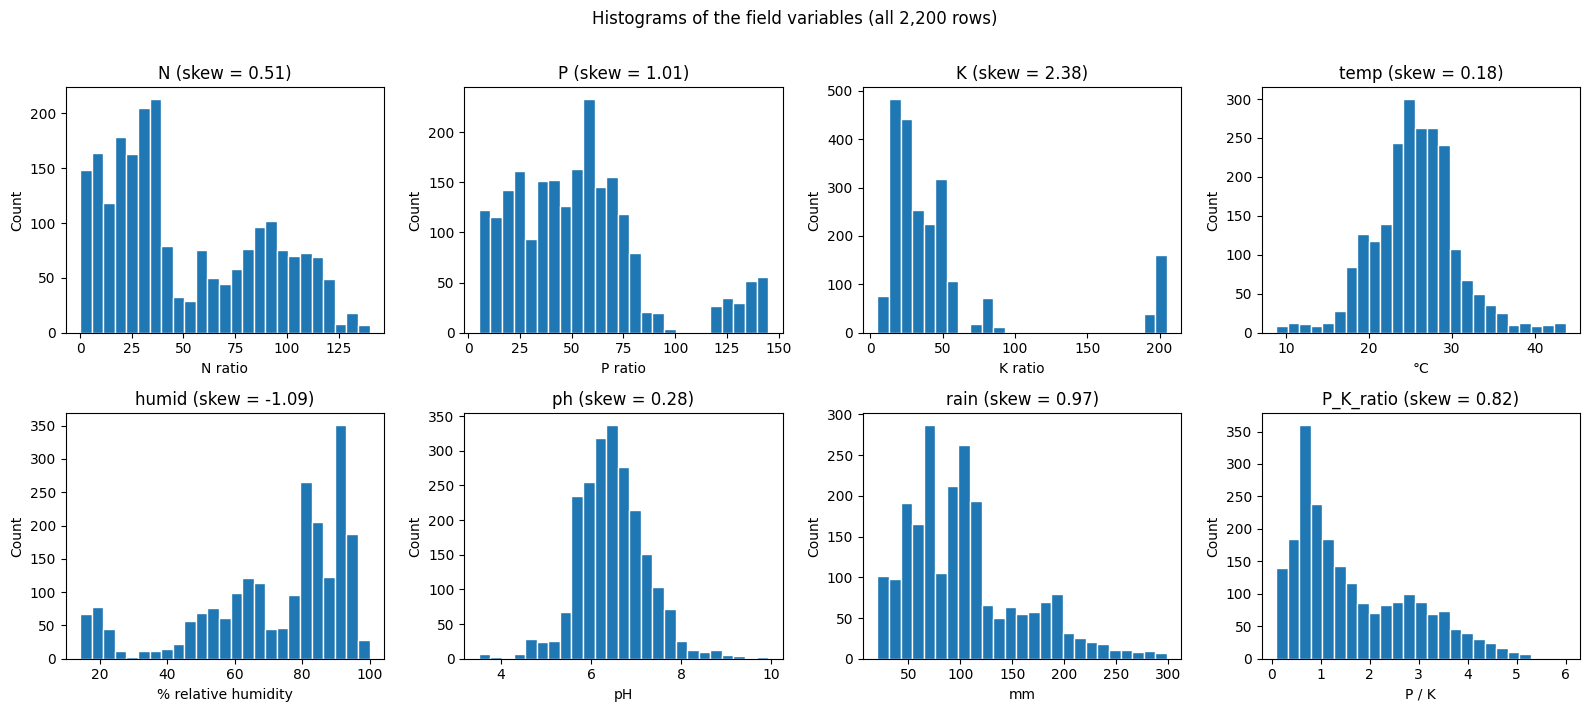

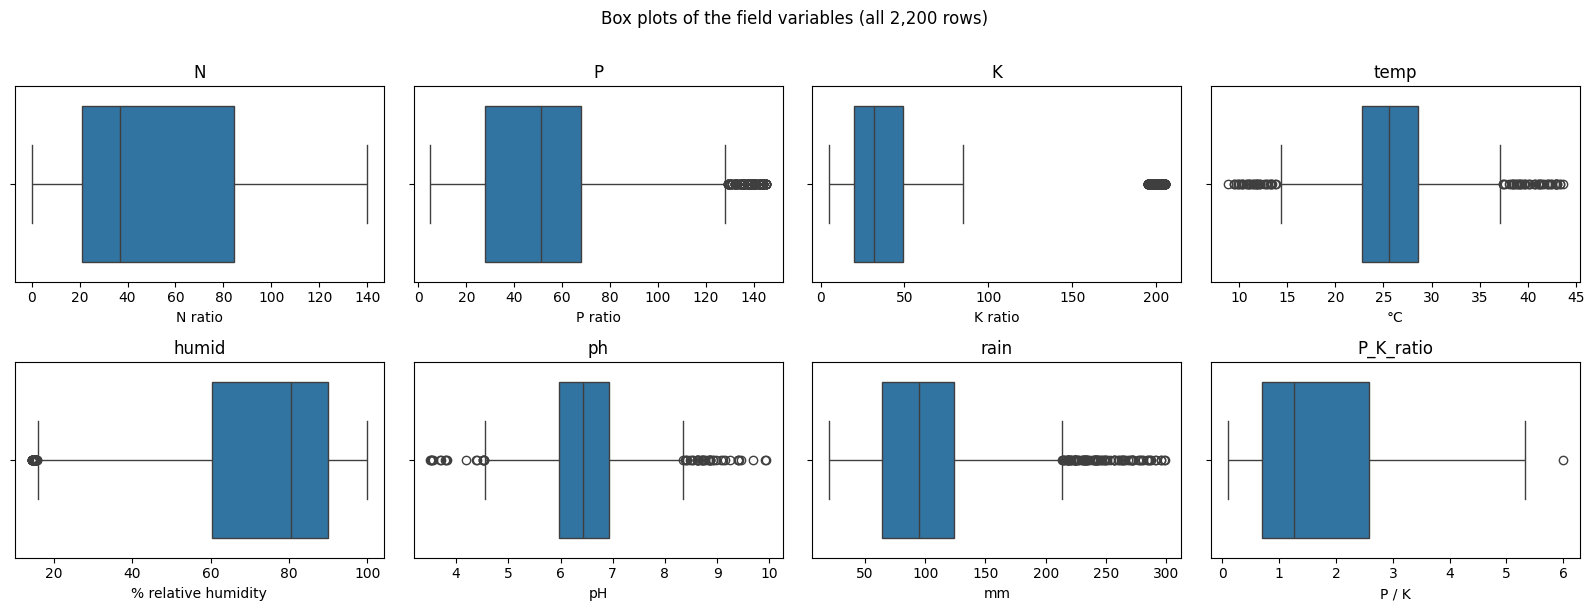

Skewness of row-level variables:
N            0.510000
P            1.011000
K            2.375000
temp         0.185000
humid       -1.092000
ph           0.284000
rain         0.966000
P_K_ratio    0.824000
dtype: float64


In [10]:
row_level = ["N", "P", "K", "temp", "humid", "ph", "rain", "P_K_ratio"]
row_level = [c for c in row_level if c in df]

display(df[row_level].describe())

UNITS = {"N": "N ratio", "P": "P ratio", "K": "K ratio", "temp": "°C", "humid": "% relative humidity",
         "ph": "pH", "rain": "mm", "P_K_ratio": "P / K"}

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), row_level):
    ax.hist(df[col], bins=25, edgecolor="white")
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
    ax.set_xlabel(UNITS.get(col, col)); ax.set_ylabel("Count")
for ax in axes.flatten()[len(row_level):]:
    ax.axis("off")
fig.suptitle("Histograms of the field variables (all 2,200 rows)", y=1.01)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.flatten(), row_level):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col); ax.set_xlabel(UNITS.get(col, col))
for ax in axes.flatten()[len(row_level):]:
    ax.axis("off")
fig.suptitle("Box plots of the field variables (all 2,200 rows)", y=1.01)
plt.tight_layout()
plt.show()

print("Skewness of row-level variables:")
print(df[row_level].skew().round(3))

### 2.7 Transformations

We use the two transformations :

* **Box-Cox** finds the power λ that makes a strictly positive variable closest to normal; we report the nearest rung of **Tukey's ladder** (2 = square, 1 = none, 0.5 = square root, 0 = log, −1 = reciprocal) so the choice is easy to explain.
* Rule: transform a **strictly positive continuous predictor** when |skewness| > 0.75.
* `ca_area_ha` and `ca_farm_value` are mostly zeros (crops not grown in Canada), so Box-Cox is impossible; we use **log(x + 1)**, the log rung of Tukey's ladder shifted by 1 so that 0 stays 0.
* The response `N` is **not** transformed so its coefficients stay in the original units (and N contains zeros, so Box-Cox cannot be applied).

New columns get a `_bc` (Box-Cox) or `_log` suffix; the originals are kept for reference but **only one version of each variable** is offered to the models.

,variable,skew_before,lambda,nearest_tukey_rung,skew_after
0,P,1.011000,0.391000,0.5 (square root),-0.030000
1,K,2.375000,-0.335000,-0.5 (reciprocal square root),-0.030000
2,temp,0.185000,NaN,not transformed,0.185000
3,humid,-1.092000,2.118000,2 (square),-0.472000
4,ph,0.284000,NaN,not transformed,0.284000
5,rain,0.966000,0.217000,0 (log),-0.014000
6,P_K_ratio,0.824000,0.247000,0 (log),-0.052000


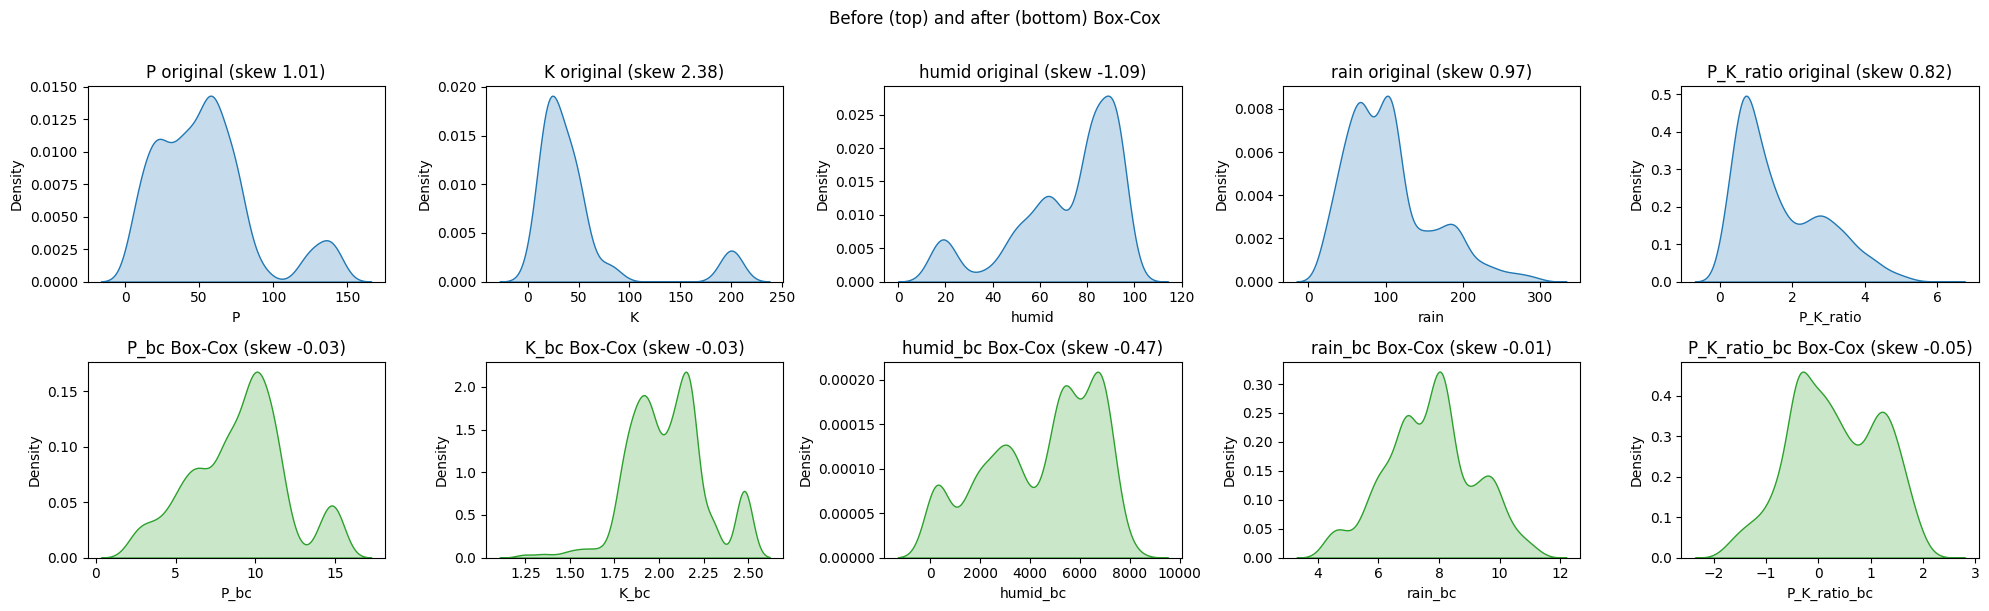

In [11]:

TUKEY = {2: "square", 1: "none", 0.5: "square root", 0: "log", -0.5: "reciprocal square root",
         -1: "reciprocal", -2: "reciprocal square"}

candidates = [c for c in ["P", "K", "temp", "humid", "ph", "rain", "P_K_ratio"] if c in df]
transform_log = []
use_version = {}     # variable -> column that the models should use

for c in candidates:
    skew = df[c].skew()
    if abs(skew) > 0.75 and (df[c] > 0).all():
        transformed, lam = boxcox(df[c])
        df[c + "_bc"] = transformed
        rung = min(TUKEY, key=lambda p: abs(p - lam))
        transform_log.append({"variable": c, "skew_before": skew, "lambda": lam,
                              "nearest_tukey_rung": f"{rung} ({TUKEY[rung]})",
                              "skew_after": pd.Series(transformed).skew()})
        use_version[c] = c + "_bc"
    else:
        transform_log.append({"variable": c, "skew_before": skew, "lambda": np.nan,
                              "nearest_tukey_rung": "not transformed", "skew_after": skew})
        use_version[c] = c

for c in ["ca_area_ha", "ca_farm_value"]:
    df[c + "_log"] = np.log1p(df[c])
    use_version[c] = c + "_log"

display(pd.DataFrame(transform_log).round(3))

bc_cols = [v for v in use_version.values() if v.endswith("_bc")]
if bc_cols:
    fig, axes = plt.subplots(2, len(bc_cols), figsize=(4 * len(bc_cols), 6), squeeze=False)
    for i, c in enumerate(bc_cols):
        orig = c.replace("_bc", "")
        sns.kdeplot(df[orig], fill=True, ax=axes[0, i])
        axes[0, i].set_title(f"{orig} original (skew {df[orig].skew():.2f})")
        sns.kdeplot(df[c], fill=True, ax=axes[1, i], color="tab:green")
        axes[1, i].set_title(f"{c} Box-Cox (skew {df[c].skew():.2f})")
    fig.suptitle("Before (top) and after (bottom) Box-Cox", y=1.01)
    plt.tight_layout()
    plt.show()

### 2.8 Converting categorical variables

* **Nominal variable (`label`)** → dummy (indicator)
  variables with k − 1 columns (`drop_first=True`).
  The 22 crop labels produce 21 dummy variables,
  avoiding perfect collinearity with the intercept.

* **Ordinal variable (`ph_class`)** → ordered codes
  0 = acidic, 1 = neutral, 2 = alkaline.

* **Binary flags** (`is_legume`, `grown_in_canada`)
  are already encoded as 0 and 1.

The `life_form` and `eco_category` variables were
removed in Section 2.5 because of missing values.

The original categorical columns are retained for
the train/test comparison using the Chi-square test.

In [12]:
nominal = [c for c in ["label", "life_form", "eco_category"] if c in df]
for c in nominal:
    df[c] = df[c].astype("category")

df["ph_class_ord"] = df["ph_class"].cat.codes          # 0 acidic, 1 neutral, 2 alkaline

def clean(name):
    return re.sub(r"[^0-9a-zA-Z_]", "_", name)

dummies = pd.get_dummies(df[nominal], prefix=nominal, drop_first=True, dtype=int)
dummies.columns = [clean(c) for c in dummies.columns]
df = pd.concat([df, dummies], axis=1)

label_dummies = [c for c in dummies.columns if c.startswith("label_")]
other_dummies = [c for c in dummies.columns if not c.startswith("label_")]
print(f"{len(label_dummies)} label dummies, {len(other_dummies)} life-form/category dummies")
print(other_dummies)

21 label dummies, 0 life-form/category dummies
[]


### 2.9 Final study file

`study` holds the usable variables (one version of each transformed variable, all categoricals converted). It is saved to `crop_study_file.csv`.

With the two crop-cycle fields dropped, the study file now contains **27 usable variables before dummy coding and 47 columns after** : 26 non-categorical variables plus the 21 crop-name dummies.

In [13]:
binary_flags = [c for c in ["is_legume", "grown_in_canada"] if c in df]
eco_numeric_cols = [c for c in df.columns if c.startswith("eco_") and pd.api.types.is_numeric_dtype(df[c])
                    and c not in dummies.columns]

# Order matters for the collinearity check in section 6: is_legume is listed before the
# category dummies, so if a "pulses" dummy duplicates it, the dummy is the one removed.
row_level_vars = ["N"] + [use_version[c] for c in ["P", "K", "temp", "humid", "ph", "rain", "P_K_ratio"]] \
                 + ["ph_class_ord"]
crop_level_vars = eco_numeric_cols + [use_version["ca_area_ha"], use_version["ca_farm_value"]] \
                  + binary_flags + other_dummies

study_cols = list(dict.fromkeys(row_level_vars + crop_level_vars + label_dummies))
study = df[study_cols].copy()
study.to_csv("crop_study_file.csv", index=False)

n_vars_before_dummies = len(row_level_vars) + len(eco_numeric_cols) + 2 + len(binary_flags) + len(nominal)
print(f"Usable variables before dummy coding : {n_vars_before_dummies}")
print(f"Usable columns in study file          : {study.shape[1]}")
assert study.shape[1] >= 25, "Study file must contain at least 25 usable variables"
print("Missing values in study file:", int(study.isna().sum().sum()))
study.info()

Usable variables before dummy coding : 27
Usable columns in study file          : 47
Missing values in study file: 0
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 47 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   N                  2200 non-null   int64  
 1   P_bc               2200 non-null   float64
 2   K_bc               2200 non-null   float64
 3   temp               2200 non-null   float64
 4   humid_bc           2200 non-null   float64
 5   ph                 2200 non-null   float64
 6   rain_bc            2200 non-null   float64
 7   P_K_ratio_bc       2200 non-null   float64
 8   ph_class_ord       2200 non-null   int8   
 9   eco_topt_min       2200 non-null   float64
 10  eco_topt_max       2200 non-null   float64
 11  eco_tabs_min       2200 non-null   float64
 12  eco_tabs_max       2200 non-null   float64
 13  eco_ropt_min       2200 non-null   float64
 14  eco_ropt_max  

### 2.10 Data sources, rationale and transformations

**Why augment at crop level.** Our Crop Recommendation dataset has no location or date column; the only key that links it to other data is the crop name (`label`). We therefore chose sources that describe *crops*, joined many-to-one on `label`.

**FAO EcoCrop.** Developed by the Food and Agriculture Organization of the UN, EcoCrop records the optimal and absolute temperature, rainfall and soil-pH limits, crop-cycle length, life form and category for thousands of plant species. It is authoritative, global (not tied to any one country) and directly answers the question our project asks: *are these conditions right for this crop?* We matched crops by scientific name to avoid ambiguity (e.g., "gram", "melon").

**Statistics Canada (tables 32-10-0359-01,
32-10-0364-01, 32-10-0365-01).** These official
tables provide harvested or cultivated area and
farm value by crop. They help us understand each
crop's relevance to Canadian agriculture.

A zero indicates that a matching record or recent
value was unavailable in the selected tables.
It does not necessarily mean that the crop is
not grown in Canada. Available values from the
latest five-year period are averaged to reduce
year-to-year variation.

**Domain-knowledge variable.** `is_legume` comes from botany (family Fabaceae). Legumes host nitrogen-fixing bacteria, which is directly relevant to our dependent variable, soil nitrogen.

**Transformations.**
* Box-Cox / Tukey's ladder was applied to strictly positive, clearly skewed predictors (rule: |skew| > 0.75). The table above shows λ, the nearest Tukey rung and the skewness before and after. As the slides note, simple prediction works best with variables that are close to normally distributed and linearly related; reducing skew moves the variables in that direction and reduces the pull of extreme values.
* log(x + 1) was used for the zero-heavy Canadian area and value variables because Box-Cox requires positive values.
* Categorical variables were dummy coded (k − 1) and `ph_class` was ordinal-coded, as described in 2.8.
* Any EcoCrop field missing for one of our crops was dropped rather than filled, so no values are estimated.

**Caveat we keep in mind for modelling.** Every crop-level variable has only 22 distinct values (one per crop). They are therefore perfectly explained by the `label` dummies, so the two groups must **not** be used in the same regression model. The regression sections use the crop-level variables (they describe *why* crops differ); the `label` dummies remain in the study file for other parts of the project.

## 3. Split into Training and Test Sets

We use an **80/20 random split** with a fixed seed. The training set is used to build every model; the test set is only used to validate them.

In [14]:
train, test = train_test_split(df, test_size=TEST_SIZE, random_state=RANDOM_STATE)

print("Train:", train.shape)
print("Test :", test.shape)

display(train[row_level_vars + nominal].describe(include="all").T)
display(test[row_level_vars + nominal].describe(include="all").T)


Train: (1760, 57)
Test : (440, 57)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
N,1760.000000,NaN,NaN,NaN,50.046023,36.886326,0.000000,21.000000,36.000000,84.000000,140.000000
P_bc,1760.000000,NaN,NaN,NaN,8.986511,2.936144,2.241391,6.855902,9.343815,10.761134,15.351905
K_bc,1760.000000,NaN,NaN,NaN,2.042671,0.214015,1.243882,1.890356,2.039672,2.168303,2.482318
temp,1760.000000,NaN,NaN,NaN,25.631198,5.012170,8.825675,22.810495,25.605637,28.568106,43.675493
humid_bc,1760.000000,NaN,NaN,NaN,4405.322036,2211.819981,130.786704,2729.648337,5117.710161,6462.110271,8059.777557
ph,1760.000000,NaN,NaN,NaN,6.460711,0.772545,3.504752,5.965508,6.419778,6.910487,9.935091
rain_bc,1760.000000,NaN,NaN,NaN,7.695137,1.473640,4.254883,6.739465,7.758264,8.522621,11.268275
P_K_ratio_bc,1760.000000,NaN,NaN,NaN,0.327331,0.854023,-1.810185,-0.341437,0.251036,1.089614,2.253014
ph_class_ord,1760.000000,NaN,NaN,NaN,0.530114,0.646152,0.000000,0.000000,0.000000,1.000000,2.000000
label,1760,22,mungbean,88,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
N,440.000000,NaN,NaN,NaN,52.575000,37.013989,0.000000,22.000000,39.000000,85.000000,133.000000
P_bc,440.000000,NaN,NaN,NaN,8.949216,3.205139,2.241391,6.822666,9.343815,10.912991,15.351905
K_bc,440.000000,NaN,NaN,NaN,2.061484,0.221760,1.347000,1.908085,2.077287,2.189878,2.482318
temp,440.000000,NaN,NaN,NaN,25.556429,5.270468,10.164313,22.636226,25.553100,28.445080,43.302049
humid_bc,440.000000,NaN,NaN,NaN,4569.453329,2169.843035,140.768597,2933.834953,5151.155072,6549.621190,8117.468693
ph,440.000000,NaN,NaN,NaN,6.504555,0.779379,3.711059,5.999210,6.458960,6.958079,9.392695
rain_bc,440.000000,NaN,NaN,NaN,7.748961,1.373179,4.240788,6.856149,7.861816,8.462723,11.237747
P_K_ratio_bc,440.000000,NaN,NaN,NaN,0.228482,0.861477,-1.810185,-0.366186,0.198223,0.939230,2.053442
ph_class_ord,440.000000,NaN,NaN,NaN,0.565909,0.644035,0.000000,0.000000,0.000000,1.000000,2.000000
label,440,22,banana,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Are the training and test sets comparable?

* **Numeric variables – Kolmogorov-Smirnov (KS) test.**
  H₀: Both samples come from the same distribution.

* **Categorical variables – Chi-square test.**
  H₀: Category proportions are the same in both sets.

At a significance level of 0.05:

* p > 0.05: No statistically significant difference detected.
* p ≤ 0.05: A statistically significant difference detected.

Similar crop proportions support the comparability
of crop-level variables but do not guarantee
identical distributions.

In [15]:
numeric_vars = [
    c for c in row_level_vars + crop_level_vars
    if c not in binary_flags + ["ph_class_ord"] + other_dummies
]

ks_rows = []
for var in numeric_vars:
    stat, p = ks_2samp(train[var], test[var])
    ks_rows.append({"variable": var, "train_mean": train[var].mean(), "test_mean": test[var].mean(),
                    "KS_stat": stat, "p_value": p,
                    "comparable": "yes" if p > ALPHA else "NO"})
ks_table = pd.DataFrame(ks_rows)
display(ks_table.round(4))

chi_rows = []
for var in nominal + ["ph_class"] + binary_flags:
    trainc = train[var].value_counts().sort_index()
    testc = test[var].value_counts().sort_index()
    table = pd.DataFrame([trainc, testc], index=["Train", "Test"]).fillna(0)
    table = table.loc[:, table.sum() > 0]
    chi2, p, dof, expected = chi2_contingency(table)
    chi_rows.append({"variable": var, "levels": table.shape[1], "chi2": chi2, "dof": dof,
                     "p_value": p, "comparable": "yes" if p > ALPHA else "NO"})
chi_table = pd.DataFrame(chi_rows)
display(chi_table.round(4))

print("Crop counts in each set:")
display(pd.DataFrame({"train": train["label"].value_counts().sort_index(),
                      "test": test["label"].value_counts().sort_index()}).T)

flagged = ks_table.loc[ks_table["comparable"] == "NO", "variable"].tolist() + \
          chi_table.loc[chi_table["comparable"] == "NO", "variable"].tolist()
print("Variables with a significant train/test difference:", flagged or "none")

,variable,train_mean,test_mean,KS_stat,p_value,comparable
0,N,50.046000,52.575000,0.050600,0.322700,yes
1,P_bc,8.986500,8.949200,0.050000,0.335800,yes
2,K_bc,2.042700,2.061500,0.054000,0.251300,yes
3,temp,25.631200,25.556400,0.033000,0.831900,yes
4,humid_bc,4405.322000,4569.453300,0.047700,0.391900,yes
5,ph,6.460700,6.504600,0.042600,0.536600,yes
6,rain_bc,7.695100,7.749000,0.055700,0.220300,yes
7,P_K_ratio_bc,0.327300,0.228500,0.064200,0.107000,yes
8,eco_topt_min,19.421600,19.586400,0.045500,0.453300,yes
9,eco_topt_max,31.756200,31.838600,0.019900,0.998800,yes


,variable,levels,chi2,dof,p_value,comparable
0,label,22,24.125000,21,0.287000,yes
1,ph_class,3,2.046800,2,0.359400,yes
2,is_legume,2,3.146100,1,0.076100,yes
3,grown_in_canada,2,0.887000,1,0.346300,yes


Crop counts in each set:


label,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,lentil,maize,mango,mothbeans,mungbean,muskmelon,orange,papaya,pigeonpeas,pomegranate,rice,watermelon
train,79,73,76,78,78,78,75,75,80,87,83,85,85,80,88,84,76,77,84,77,84,78
test,21,27,24,22,22,22,25,25,20,13,17,15,15,20,12,16,24,23,16,23,16,22


Variables with a significant train/test difference: none


#### Visual comparison of the two sets

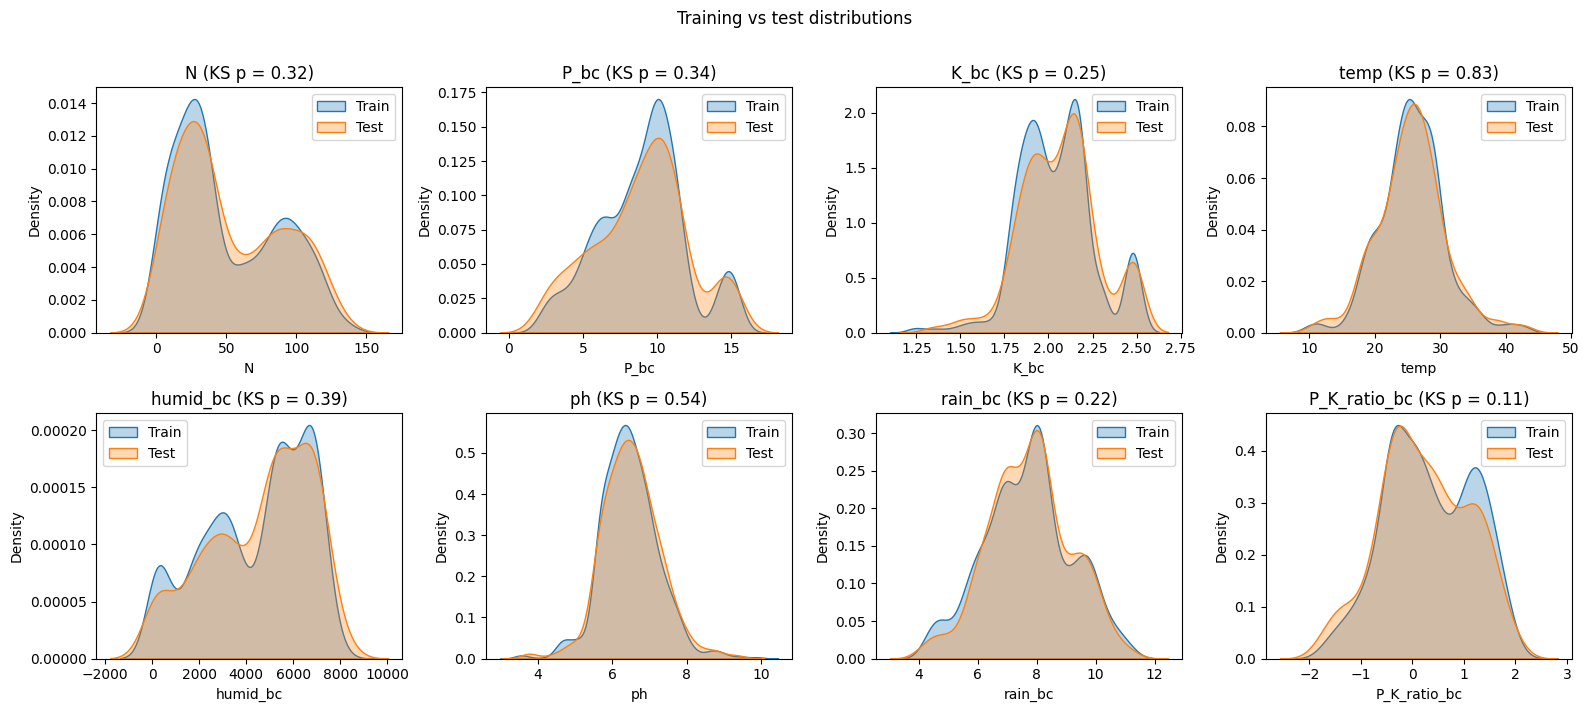

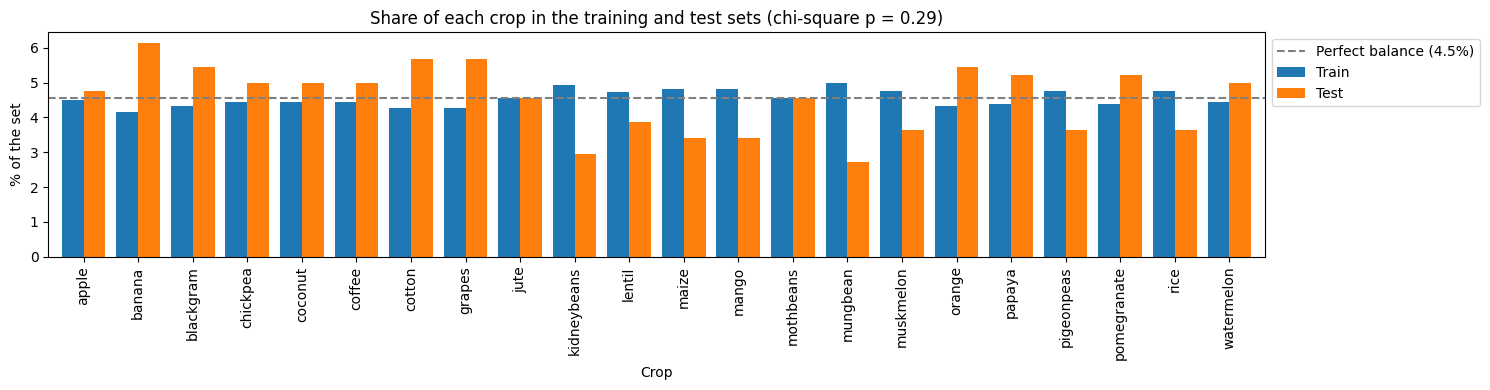

In [16]:
cont = [c for c in row_level_vars if c != "ph_class_ord"]
ks_p = ks_table.set_index("variable")["p_value"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), cont):
    sns.kdeplot(train[col], ax=ax, fill=True, alpha=0.3, label="Train")
    sns.kdeplot(test[col], ax=ax, fill=True, alpha=0.3, label="Test")
    ax.set_title(f"{col} (KS p = {ks_p[col]:.2f})")
    ax.legend()
for ax in axes.flatten()[len(cont):]:
    ax.axis("off")
fig.suptitle("Training vs test distributions", y=1.01)
plt.tight_layout()
plt.show()

shares = pd.DataFrame({"Train": train["label"].value_counts(normalize=True),
                       "Test": test["label"].value_counts(normalize=True)}).sort_index() * 100
ax = shares.plot.bar(figsize=(15, 4), width=0.8)
ax.axhline(100 / 22, color="grey", linestyle="--", label="Perfect balance (4.5%)")
ax.set_ylabel("% of the set"); ax.set_xlabel("Crop")
ax.set_title(f"Share of each crop in the training and test sets (chi-square p = {chi_table.set_index('variable').loc['label', 'p_value']:.2f})")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

#### Train/test comparison — discussion

The dataset was randomly divided into 1,760 training
observations (80%) and 440 testing observations (20%).

* All 23 numerical variables passed the KS test
  at the 0.05 significance level.
* All four categorical variables passed the
  Chi-square test.
* The crop distribution is comparable between
  the two sets (p = 0.2870).
* The legume indicator has a p-value of 0.0761,
  which is relatively close to the significance
  threshold but is not statistically significant.

No statistically significant differences were
detected between the training and test sets.
These results support their comparability for
regression analysis.

The crop-level variables are repeated across
observations belonging to the same crop.
Therefore, validation measures prediction on
held-out observations, not entirely unseen crops.

The Box-Cox transformations were fitted before
splitting the data, which is a preprocessing
limitation of this analysis.

## 4. Dependent Variable

**Y = `N`, the soil nitrogen ratio recorded in the dataset.**

* **Business question:** Which crop characteristics
  and growing conditions are associated with soil
  nitrogen levels, and how accurately can we predict N?

* **Why N is a suitable regression target:** It is a
  numerical variable ranging from 0 to 140 and varies
  considerably between crops. The augmented variables,
  such as legume status and environmental requirements,
  provide additional predictors for the analysis.

* **Leakage check:** No predictor is directly calculated
  from N. The P_K_ratio uses phosphorus and potassium
  rather than nitrogen.

The analysis identifies associations with soil nitrogen
levels, not actual fertilizer requirements.

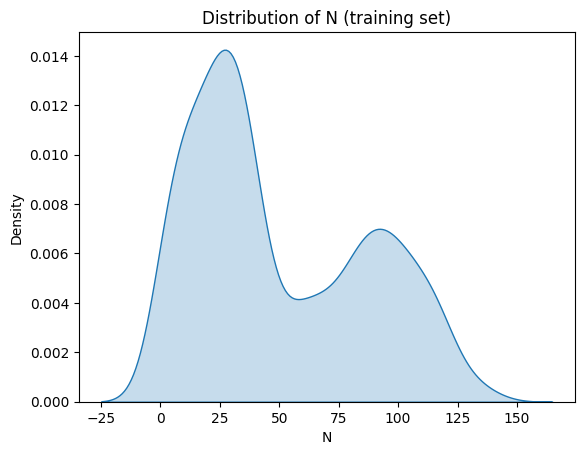

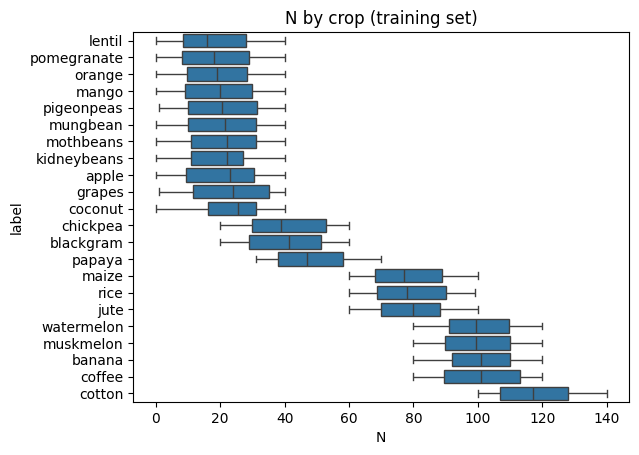

count   1760.000000
mean      50.046023
std       36.886326
min        0.000000
25%       21.000000
50%       36.000000
75%       84.000000
max      140.000000
Name: N, dtype: float64


In [17]:
Y = "N"

sns.kdeplot(train[Y], fill=True)
plt.title("Distribution of N (training set)")
plt.show()

sns.boxplot(data=train, x=Y, y="label", order=train.groupby("label")[Y].median().sort_values().index)
plt.title("N by crop (training set)")
plt.show()

print(train[Y].describe())

### Correlation with N (training set only)

Spearman is used because several variables are skewed, binary or ordinal . Pearson is shown beside it because simple linear regression fits a straight line, so it is the Pearson correlation that tells us how much a single predictor can explain (R² = Pearson r²).

,pearson_r,spearman_r
is_legume,-0.461000,-0.420000
K,-0.129000,0.220000
P,-0.233000,-0.166000
ph,0.095000,0.140000
humid,0.202000,0.079000
temp,0.019000,0.018000
rain,0.067000,0.018000


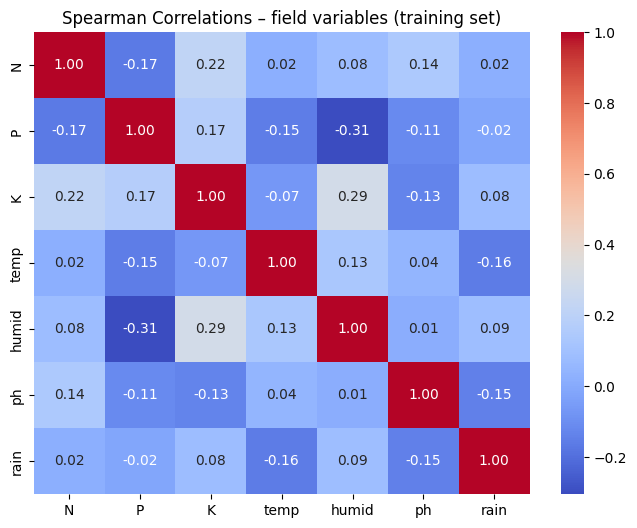

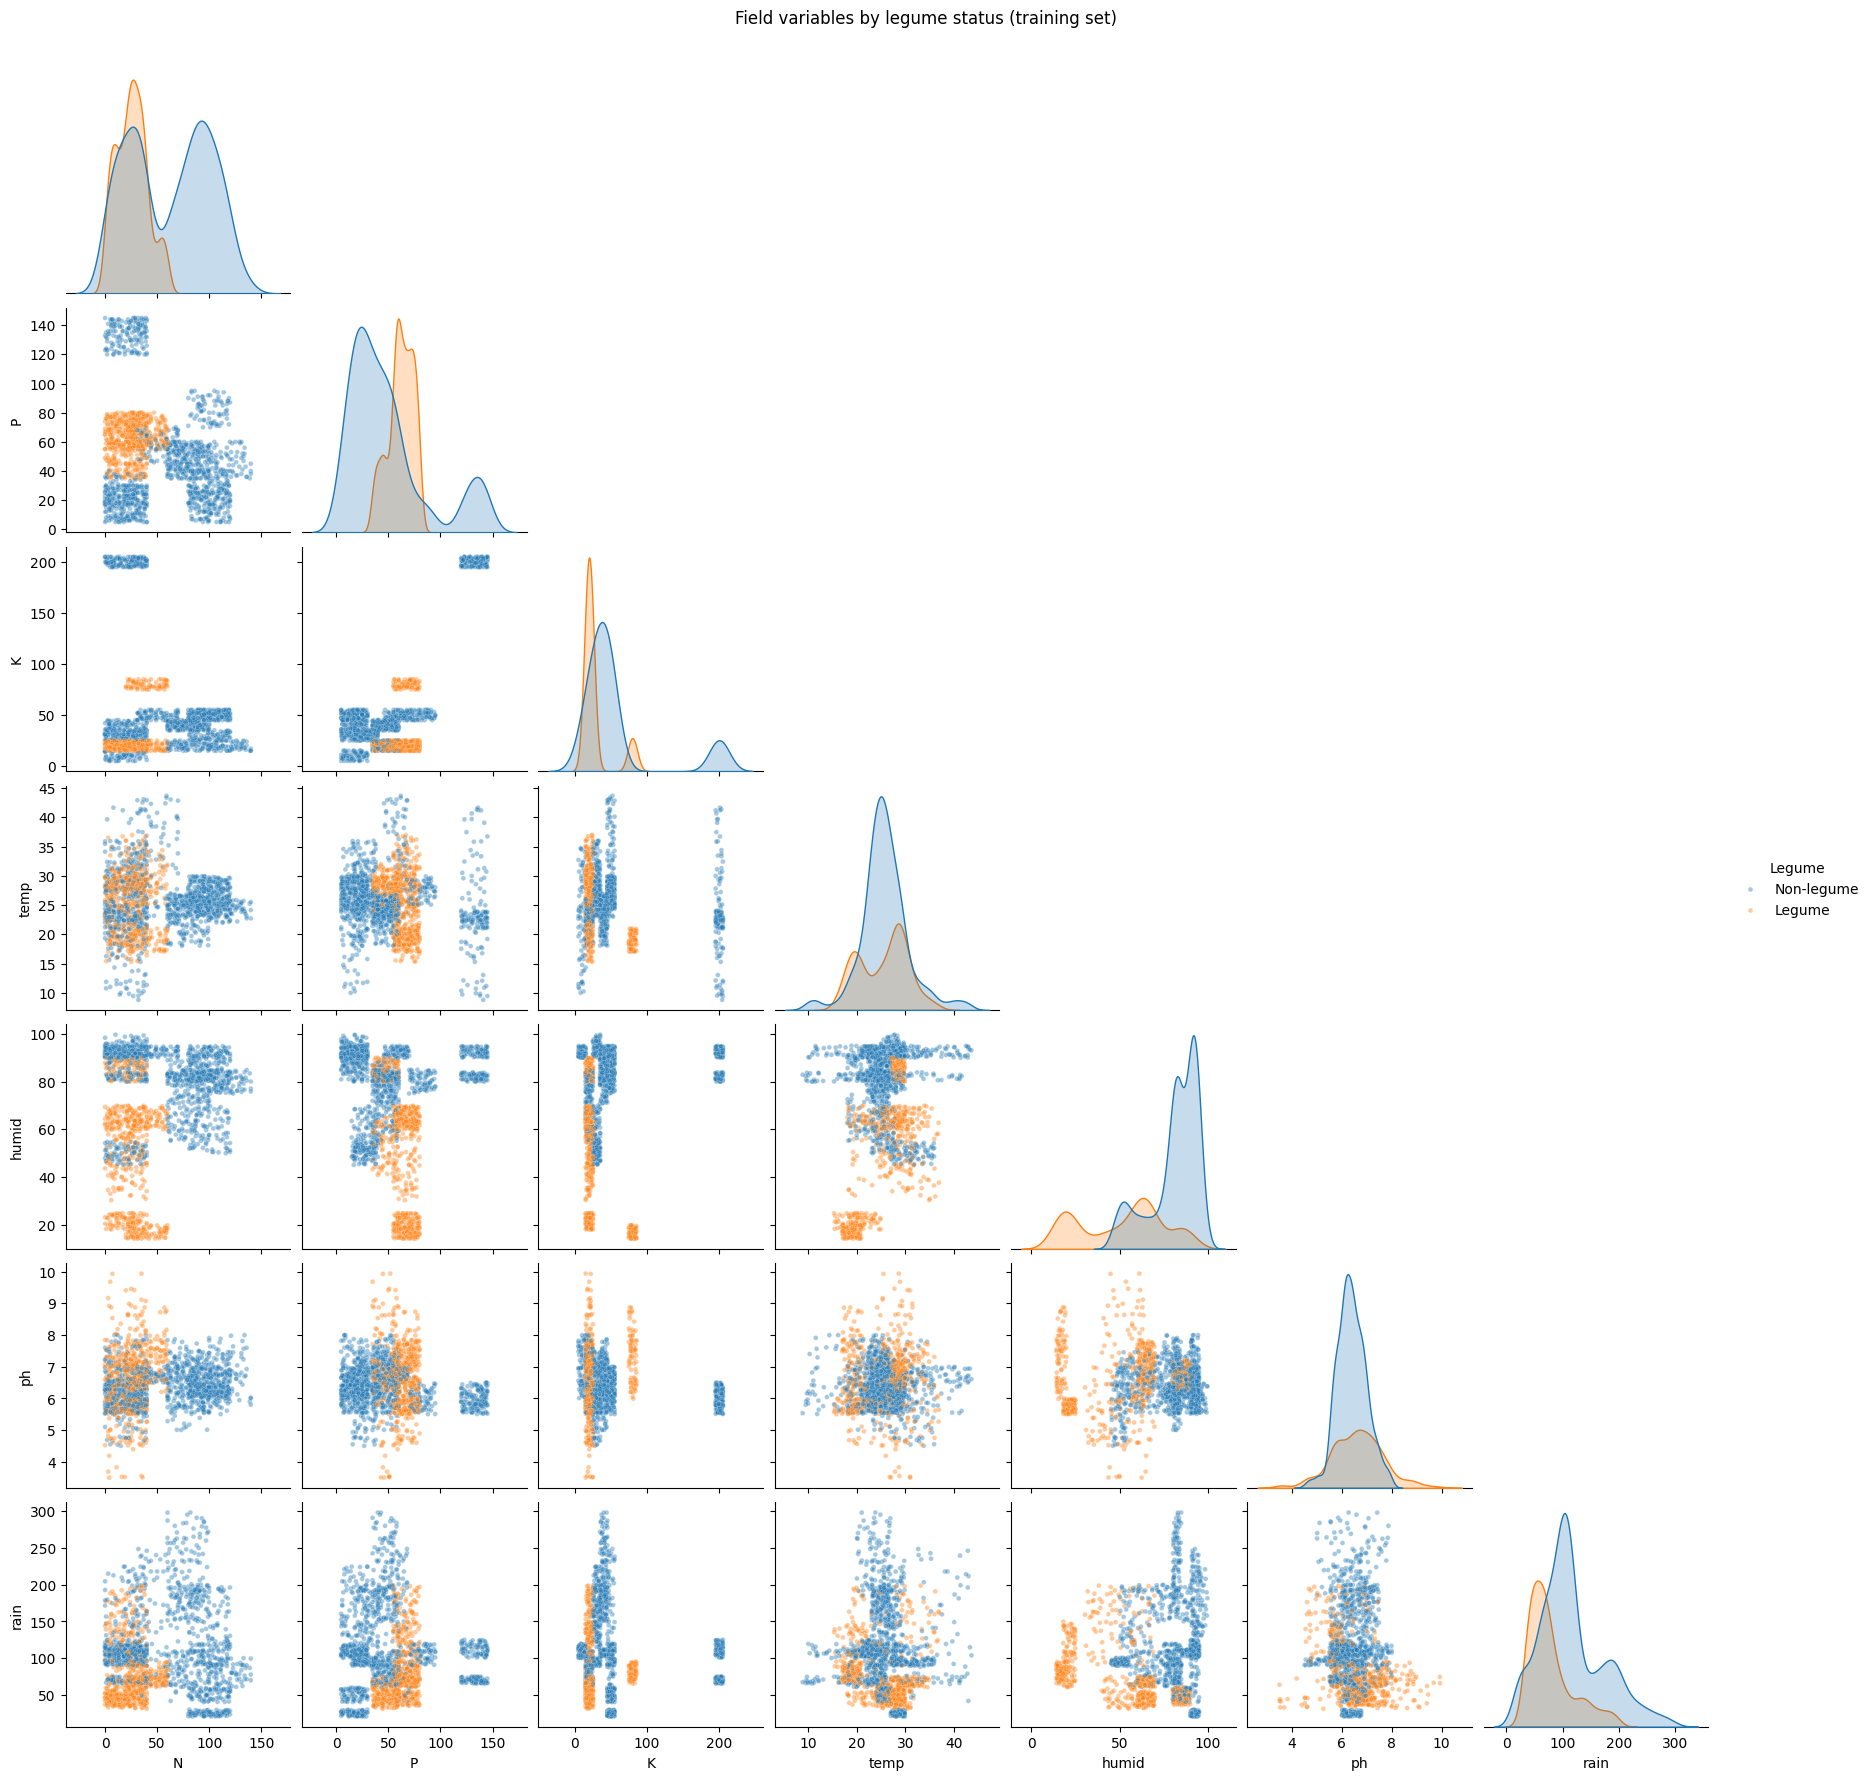

In [18]:
field_vars = ["N", "P", "K", "temp", "humid", "ph", "rain"]

corr_table = pd.DataFrame({
    "pearson_r": train[field_vars + ["is_legume"]].corr()["N"],
    "spearman_r": train[field_vars + ["is_legume"]].corr(method="spearman")["N"],
}).drop("N").sort_values("spearman_r", key=abs, ascending=False)
display(corr_table.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(train[field_vars].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Spearman Correlations – field variables (training set)")
plt.show()

pair_data = train[field_vars].assign(Legume=train["is_legume"].map({0: "Non-legume", 1: "Legume"}))
g = sns.pairplot(pair_data, hue="Legume", corner=True, plot_kws={"alpha": 0.4, "s": 12})
g.fig.suptitle("Field variables by legume status (training set)", y=1.02)
plt.show()

The heatmap below adds the crop-level (augmented) variables and shows N's 12 strongest Spearman correlates.

,spearman_r_with_N
eco_rabs_min,0.457000
is_legume,-0.420000
eco_tabs_min,0.404000
eco_ropt_min,0.326000
eco_topt_width,0.261000
eco_phabs_min,0.258000
K_bc,0.220000
eco_phopt_min,0.188000
eco_phabs_max,0.185000
eco_topt_max,0.180000


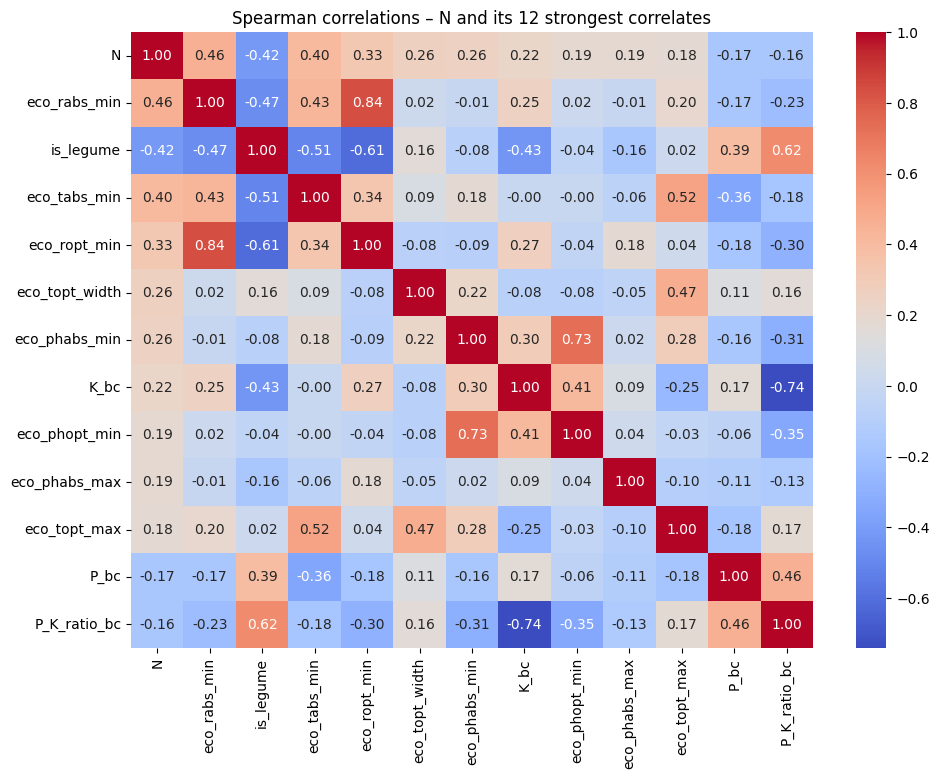

In [19]:
candidate_predictors = [c for c in row_level_vars + crop_level_vars if c != Y]

corr_y = train[candidate_predictors + [Y]].corr(method="spearman")[Y].drop(Y).sort_values(key=abs, ascending=False)
display(corr_y.to_frame("spearman_r_with_N").round(3))

top = corr_y.index[:12].tolist()
plt.figure(figsize=(11, 8))
sns.heatmap(train[[Y] + top].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Spearman correlations – N and its 12 strongest correlates")
plt.show()

## 5. Simple Linear Regression – two models

We compare two single predictors that represent the two kinds of information in our study file:

* **Model A – `N ~ P`**: a **row-level, measured** field condition from the original dataset (the soil phosphorus ratio), chosen with the candidate table below.
* **Model B – `N ~ is_legume`**: a **crop-level** characteristic added by our augmentation (is the crop a nitrogen-fixing legume?). A binary predictor is allowed in SLR: β₀ is the mean N of non-legumes and β₁ is the difference in mean N for legumes.

Both models are fitted on the **training** set only, then evaluated on the test set.

In [20]:
def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))


cand_rows = []

for x in ["P", "K", "temp", "humid", "ph", "rain", "is_legume"]:
    m = sm.OLS(train[Y], sm.add_constant(train[[x]])).fit()

    cand_rows.append({
        "predictor": x,
        "level": "crop" if x == "is_legume" else "field",
        "spearman_r": spearmanr(train[x], train[Y])[0],
        "slope": m.params[x],
        "adj_R2": m.rsquared_adj,
        "F_p_value": m.f_pvalue,
        "train_RMSE": rmse(train[Y], m.fittedvalues)
    })

candidates_slr = pd.DataFrame(cand_rows)

candidates_slr["slope_sign_matches_spearman"] = (
    np.sign(candidates_slr["slope"])
    == np.sign(candidates_slr["spearman_r"])
)

display(
    candidates_slr.sort_values(
        "adj_R2", ascending=False
    ).round(4)
)

baseline_test_rmse = rmse(
    test[Y], np.full(len(test), train[Y].mean())
)

,predictor,level,spearman_r,slope,adj_R2,F_p_value,train_RMSE,slope_sign_matches_spearman
6,is_legume,crop,-0.419600,-36.255100,0.212400,0.000000,32.717500,True
0,P,field,-0.166100,-0.263800,0.053600,0.000000,35.863000,True
3,humid,field,0.078500,0.331900,0.040100,0.000000,36.118800,True
1,K,field,0.220000,-0.095400,0.016100,0.000000,36.567300,False
4,ph,field,0.140300,4.551600,0.008500,0.000100,36.707900,True
5,rain,field,0.018000,0.044200,0.003900,0.005200,36.793900,True
2,temp,field,0.018400,0.138700,-0.000200,0.429500,36.869300,True


#### Selection of the two simple linear regression models

We compared seven candidate predictors using the
training dataset, based on adjusted R², F-test
significance, training RMSE and coefficient direction.

* **Model A: N ~ P (phosphorus).**
  P is the best-performing field-level predictor
  among the candidates, with adjusted R² = 0.0536
  and training RMSE = 35.8630. We use its original
  scale to keep the regression coefficient easy
  to interpret.

* **Model B: N ~ is_legume.**
  This is the best-performing predictor among
  the candidates, with adjusted R² = 0.2124
  and training RMSE = 32.7175.

Both predictors have statistically significant
relationships with N, and their regression slope
directions agree with their Spearman correlations.

The test dataset is reserved for evaluating the
predictive performance of the two selected models.

Spearman correlation (N vs P): -0.1661  p-value: 0.0000
Spearman correlation (N vs is_legume): -0.4196  p-value: 0.0000


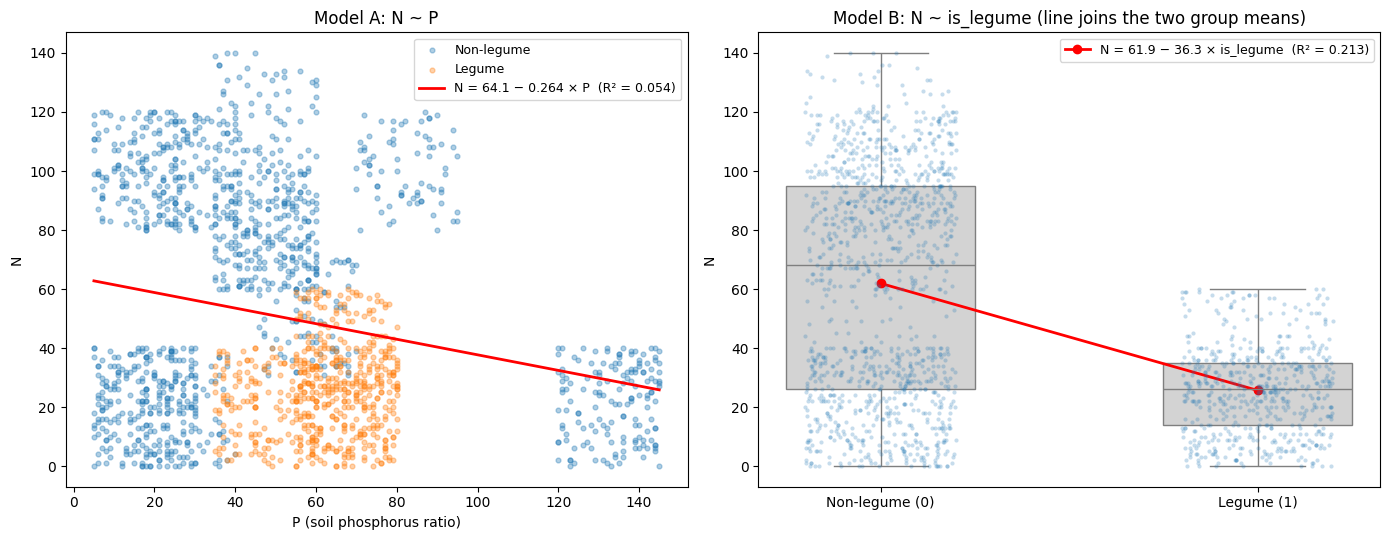

In [21]:
SLR_A = "P"
SLR_B = "is_legume"

# Scatter plots and Spearman correlations (training set)
for x in [SLR_A, SLR_B]:
    r, p = spearmanr(train[x], train[Y])
    print(f"Spearman correlation (N vs {x}): {r:.4f}  p-value: {p:.4f}")

# Preliminary models
X_a = sm.add_constant(train[[SLR_A]])
slr_a = sm.OLS(train[Y], X_a).fit()

X_b = sm.add_constant(train[[SLR_B]])
slr_b = sm.OLS(train[Y], X_b).fit()

# Model A coloured by legume status; Model B as a box plot with the line joining the two group means
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
for flag, colour, name in [(0, "tab:blue", "Non-legume"), (1, "tab:orange", "Legume")]:
    part = train[train["is_legume"] == flag]
    ax.scatter(part[SLR_A], part[Y], alpha=0.35, s=12, color=colour, label=name)
xs = np.linspace(train[SLR_A].min(), train[SLR_A].max(), 100)
ax.plot(xs, slr_a.params["const"] + slr_a.params[SLR_A] * xs, color="red", linewidth=2,
        label=f"N = {slr_a.params['const']:.1f} − {abs(slr_a.params[SLR_A]):.3f} × P  (R² = {slr_a.rsquared:.3f})")
ax.set_xlabel("P (soil phosphorus ratio)"); ax.set_ylabel("N")
ax.set_title("Model A: N ~ P")
ax.legend(fontsize=9)

ax = axes[1]
sns.boxplot(data=train, x=SLR_B, y=Y, ax=ax, width=0.5, color="lightgrey")
sns.stripplot(data=train, x=SLR_B, y=Y, ax=ax, alpha=0.25, size=3, color="tab:blue", jitter=0.2)
means = [slr_b.params["const"], slr_b.params["const"] + slr_b.params[SLR_B]]
ax.plot([0, 1], means, color="red", marker="o", linewidth=2,
        label=f"N = {means[0]:.1f} − {abs(slr_b.params[SLR_B]):.1f} × is_legume  (R² = {slr_b.rsquared:.3f})")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Non-legume (0)", "Legume (1)"])
ax.set_xlabel(""); ax.set_ylabel("N")
ax.set_title("Model B: N ~ is_legume (line joins the two group means)")
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

#### Model summaries

Check the F-statistic p-value, R² / adjusted R², the t-test p-values, whether the coefficients make sense, and RMSE on train **and** test.


In [22]:
def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))


def evaluate(name, model, X_train, X_test):
    pred_trn = model.predict(X_train)
    pred_tst = model.predict(X_test)
    return {"Model": name,
            "F_stat": model.fvalue, "F_p_value": model.f_pvalue,
            "R2": model.rsquared, "Adj_R2": model.rsquared_adj,
            "n_predictors": int(model.df_model),
            "Train_RMSE": rmse(train[Y], pred_trn), "Test_RMSE": rmse(test[Y], pred_tst),
            "RMSE_gap_%": 100 * (rmse(test[Y], pred_tst) - rmse(train[Y], pred_trn)) / rmse(train[Y], pred_trn)}


print("Model A summary")
print(slr_a.summary())
print("\nModel B summary")
print(slr_b.summary())

slr_results = pd.DataFrame([
    evaluate(f"A: N ~ {SLR_A}", slr_a, X_a, sm.add_constant(test[[SLR_A]])),
    evaluate(f"B: N ~ {SLR_B}", slr_b, X_b, sm.add_constant(test[[SLR_B]])),
]).set_index("Model")
# How much better than predicting the training mean for every field
slr_results["Test_RMSE_better_than_baseline_%"] = 100 * (baseline_test_rmse - slr_results["Test_RMSE"]) / baseline_test_rmse
display(slr_results.round(4))

print("\nCoefficient t-tests:")
for name, m in [("A", slr_a), ("B", slr_b)]:
    print(name, "slope =", round(m.params.iloc[1], 4), " t =", round(m.tvalues.iloc[1], 3),
          " p =", f"{m.pvalues.iloc[1]:.2e}")

Model A summary
                            OLS Regression Results                            
Dep. Variable:                      N   R-squared:                       0.054
Model:                            OLS   Adj. R-squared:                  0.054
Method:                 Least Squares   F-statistic:                     100.7
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           4.42e-23
Time:                        18:58:35   Log-Likelihood:                -8797.6
No. Observations:                1760   AIC:                         1.760e+04
Df Residuals:                    1758   BIC:                         1.761e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         64.0868      1.640    

,F_stat,F_p_value,R2,Adj_R2,n_predictors,Train_RMSE,Test_RMSE,RMSE_gap_%,Test_RMSE_better_than_baseline_%
Model,,,,,,,,,
A: N ~ P,100.697200,0.000000,0.054200,0.053600,1,35.863000,36.102800,0.668400,2.578500
B: N ~ is_legume,475.274400,0.000000,0.212800,0.212400,1,32.717500,33.709500,3.032000,9.036500



Coefficient t-tests:
A slope = -0.2638  t = -10.035  p = 4.42e-23
B slope = -36.2551  t = -21.801  p = 1.84e-93


#### Summary– which SLR model is superior?



| Measure (training n = 1,760; test n = 440) | Model A: N ~ P | Model B: N ~ is_legume |
|---|---|---|
| F-statistic (p-value) | 100.7 (p ≈ 4.4 × 10⁻²³) | 475.3 (p ≈ 1.8 × 10⁻⁹³) |
| R² / Adjusted R² | 0.054 / 0.054 | 0.213 / 0.212 |
| Slope (t, p) | −0.264 per unit of P (t = −10.0, p < 0.001) | −36.3 (t = −21.8, p < 0.001) |
| Intercept | 64.1 | 61.9 |
| Train RMSE / Test RMSE | 35.9 / 36.1 | 32.7 / 33.7 |
| Train→test RMSE change | +0.7 % | +3.0 % |
| Test RMSE better than baseline (37.1) | 2.6 % | 9.0 % |

We compare the models using the statistical measures
covered in class:

1. **F-statistic:** Both models are statistically
   significant. Model B has a higher F-statistic
   (475.3 compared with 100.7).

2. **Adjusted R²:** Model A explains approximately
   5% of the variation in N, while Model B explains
   approximately 21%.

3. **t-tests:** Both regression slopes are statistically
   significant (p < 0.001).

4. **Coefficient interpretation:** Model A predicts
   a decrease of approximately 0.264 in N for each
   one-unit increase in P. Model B predicts approximately
   36.3 lower N for legumes compared with non-legumes.
   These relationships represent associations rather
   than causal effects.

5. **RMSE:** Model B has a lower test RMSE
   (33.7 compared with 36.1). Both models have
   relatively small differences between training
   and testing RMSE.

6. **Baseline comparison:** Model A reduces test
   RMSE by approximately 2.6%, while Model B
   reduces it by approximately 9.0%.

**Conclusion:** Model B (N ~ is_legume) is superior
among the two models because it has a higher adjusted R²,
higher F-statistic and lower test RMSE.

However, approximately 79% of the variation in N
remains unexplained by Model B. Multiple linear
regression will investigate whether combining
field-level and augmented crop-level predictors
can improve prediction accuracy.